Loan Approval classification

In [23]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [24]:
# Data Prepration
df = pd.read_csv("loan_data.csv")
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


In [25]:
#EDA
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [26]:
df.tail()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1
44999,24.0,male,High School,51609.0,1,RENT,6665.0,DEBTCONSOLIDATION,17.05,0.13,3.0,628,No,1


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

In [28]:
df.describe()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


In [29]:
#
df[df.duplicated()]

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status


In [30]:
df["person_age"]=df["person_age"].astype(int)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  int64  
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

<Axes: xlabel='loan_status', ylabel='count'>

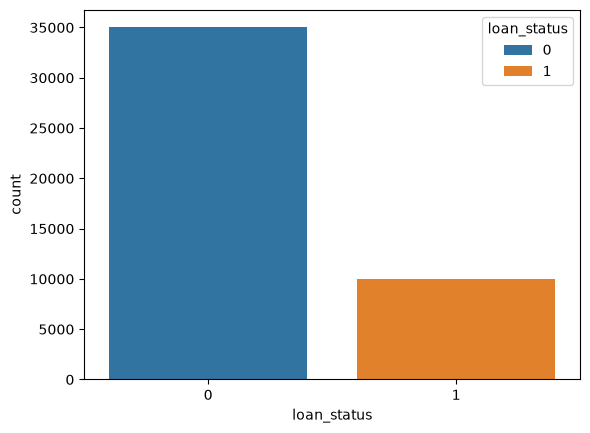

In [32]:
sns.countplot(x="loan_status",data = df, hue = "loan_status")

<Axes: xlabel='person_age', ylabel='Count'>

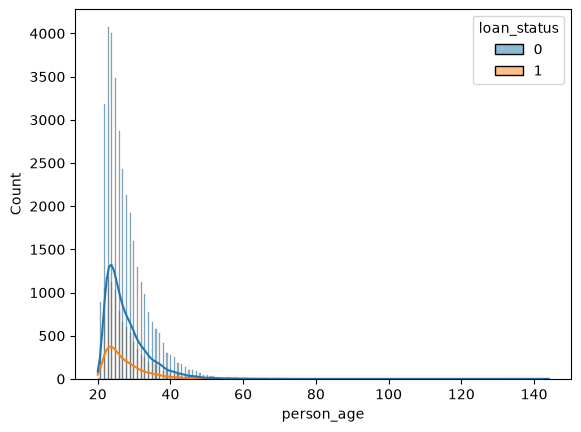

In [33]:
#People who are inbetween 20 to 40 are applying for loan
sns.histplot(x="person_age",data=df,hue="loan_status",kde=True)

<Axes: xlabel='loan_status', ylabel='person_income'>

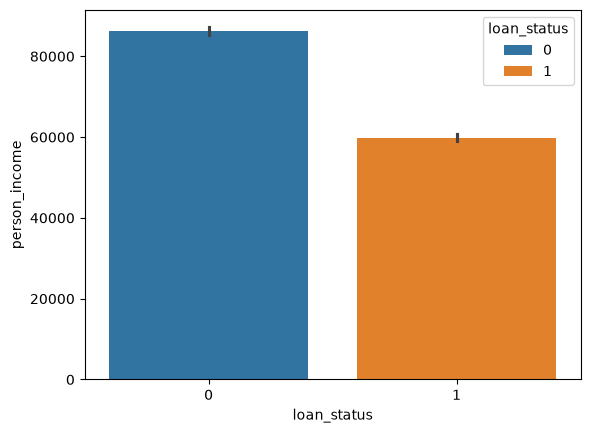

In [34]:
sns.barplot(x="loan_status",y="person_income",data=df,hue="loan_status")

Multi -Model Training

In [35]:
x= df.drop("loan_status",axis=1)
y= df["loan_status"]
y

0        1
1        0
2        1
3        1
4        1
        ..
44995    1
44996    1
44997    1
44998    1
44999    1
Name: loan_status, Length: 45000, dtype: int64

In [36]:
# Divide the data into training and testing
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.3,random_state=42)

In [37]:
#Divide the data into numeric and object

num_col = xtrain.select_dtypes(include="number").columns
cat_col = xtrain.select_dtypes(include="object").columns
cat_col

C:\Users\NITHISH_ZORO\AppData\Local\Temp\ipykernel_15412\2437495242.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = xtrain.select_dtypes(include="object").columns


Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='str')

In [38]:
# Initialize all the model pipeline

models = {
    "Logistic Regression":Pipeline([("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_col),("encoder",OneHotEncoder(),cat_col)])),
                                    ("model",LogisticRegression(class_weight="balanced"))]),

            "Naive_Bayes":Pipeline([("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_col),("encoder",OneHotEncoder(),cat_col)])),
                                    ("model",GaussianNB())]),

                     "SVM":Pipeline([("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_col),("encoder",OneHotEncoder(),cat_col)])),
                                    ("model",SVC())]),

         "Decision_Tree":Pipeline([("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_col),("encoder",OneHotEncoder(),cat_col)])),
                                    ("model",DecisionTreeClassifier(max_depth=6))]),
                                    
        "Random_forest":Pipeline([("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_col),("encoder",OneHotEncoder(),cat_col)])),
                                    ("model",RandomForestClassifier(n_estimators=100,max_depth=6,random_state=42))])                                                                                                 
}
models

{'Logistic Regression': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                   Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
        'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
        'credit_score'],
       dtype='str')),
                                                  ('encoder', OneHotEncoder(),
                                                   Index(['person_gender', 'person_education', 'person_home_ownership',
        'loan_intent', 'previous_loan_defaults_on_file'],
       dtype='str'))])),
                 ('model', LogisticRegression(class_weight='balanced'))]),
 'Naive_Bayes': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                   Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
        'loan_

In [39]:
# Train the multiple model pipeline and save the accuracy
model_perf={}
for model_name,pipeline in models.items():
    #Train piprline
    pipeline.fit(xtrain,ytrain)

    # prediction
    ypred = pipeline.predict(xtest)

    #Accuracy
    accuracy = accuracy_score(ytest,ypred)

    model_perf[model_name]=accuracy
model_perf


{'Logistic Regression': 0.8566666666666667,
 'Naive_Bayes': 0.7327407407407407,
 'SVM': 0.9137037037037037,
 'Decision_Tree': 0.9112592592592592,
 'Random_forest': 0.9188888888888889}

In [40]:
# Save the model performance tabel

perf_df = pd.Series(model_perf)
perf_df = pd.DataFrame(perf_df,columns = ["accuracy"])
perf_df.to_csv("models_perf_dataset.csv")
perf_df

,accuracy
Logistic Regression,0.856667
Naive_Bayes,0.732741
SVM,0.913704
Decision_Tree,0.911259
Random_forest,0.918889


In [41]:
# fetch best model and best accurarcy

best = max(model_perf.items(), key = lambda x:x[1])
print("Best Model:",best[0])
print("Best Model Accuracy:",best[1])

Best Model: Random_forest
Best Model Accuracy: 0.9188888888888889


In [42]:
# Parsing teshnique
#   1)JSON
#   2)Pickel
#  dumps->encryption,loads->decryptions

# Save the best pipeline

import pickle
best_pipeline = models[best[0]]
with open("best_model_pipeline.pkl","wb") as file:
    pickle.dump(best_pipeline,file)
    print("Best Model Pipeline Saves Successfully")

Best Model Pipeline Saves Successfully


In [43]:
best_pipeline.predict(xtest)

array([0, 0, 1, ..., 0, 0, 0], shape=(13500,))

In [44]:
# Save the cleaned dataframe
df.to_csv("cleaned_data.csv")

In [46]:
xtrain.columns

Index(['person_age', 'person_gender', 'person_education', 'person_income',
       'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file'],
      dtype='str')